# Atividade 2 — Regressão linear múltipla: preço de imóveis na Califórnia

## Objetivo

Treinar uma regressão linear com **várias variáveis de entrada** (regressão múltipla) em PyTorch, para prever o preço médio dos imóveis de quarteirões censitários da Califórnia (dataset *California Housing*).

O pipeline é o mesmo do notebook **2.6** (`nn.Linear`, `nn.MSELoss`, `optim.SGD`, divisão treino/validação/teste, padronização com `StandardScaler` ajustado só no treino, funções `train_epoch`/`validate_epoch`). A diferença é que o 2.6 tinha 1 variável de entrada (anos de experiência) e aqui são 8 variáveis: o modelo passa de `nn.Linear(1, 1)` para **`nn.Linear(8, 1)`**.

## Importação das bibliotecas

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim
import matplotlib.pyplot as plt

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Leitura

O dataset vem embutido no scikit-learn e baixa automaticamente, sem login. Cada linha é um **quarteirão censitário** (*block group*) da Califórnia, levantado no censo de 1990; a saída é o **valor mediano dos imóveis** daquele quarteirão.

A documentação do scikit-learn informa que o alvo original vem em **centenas de milhares de dólares**; aqui ele já é convertido para dólares (`y * 100_000`), para que RMSE e previsões fiquem numa unidade mais direta de interpretar.

In [2]:
dados = fetch_california_housing(as_frame=True)
X = dados.data
y = dados.target * 100_000   # de "centenas de milhares de US$" para US$

n_samples = X.shape[0]
print('X.shape:', X.shape)
print('y.shape:', y.shape)
X.head()

X.shape: (20640, 8)
y.shape: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### O que cada variável significa

| Coluna | Significado |
|---|---|
| `MedInc` | renda média do quarteirão (em dezenas de milhares de dólares) |
| `HouseAge` | idade mediana dos imóveis do quarteirão (anos) |
| `AveRooms` | número médio de cômodos por domicílio |
| `AveBedrms` | número médio de quartos (*bedrooms*) por domicílio |
| `Population` | população do quarteirão |
| `AveOccup` | número médio de moradores por domicílio |
| `Latitude` | latitude do quarteirão |
| `Longitude` | longitude do quarteirão |

A saída `y` é o **valor mediano dos imóveis do quarteirão, em dólares**.

In [3]:
X.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [4]:
y.describe()

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: MedHouseVal, dtype: float64

### Dispersão de algumas variáveis contra o preço

Antes de ajustar qualquer modelo, vale olhar como cada variável se relaciona (isoladamente) com o preço.

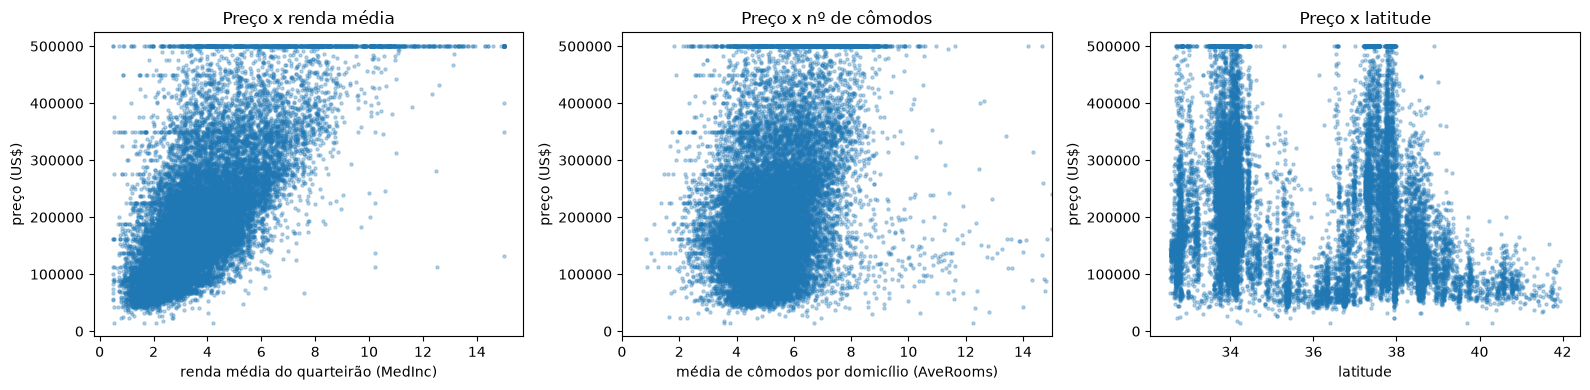

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(X['MedInc'], y, s=5, alpha=0.3)
axes[0].set_xlabel('renda média do quarteirão (MedInc)')
axes[0].set_ylabel('preço (US$)')
axes[0].set_title('Preço x renda média')

axes[1].scatter(X['AveRooms'], y, s=5, alpha=0.3)
axes[1].set_xlim(0, 15)   # alguns quarteirões têm AveRooms muito alto (outliers) e distorcem a escala
axes[1].set_xlabel('média de cômodos por domicílio (AveRooms)')
axes[1].set_ylabel('preço (US$)')
axes[1].set_title('Preço x nº de cômodos')

axes[2].scatter(X['Latitude'], y, s=5, alpha=0.3)
axes[2].set_xlabel('latitude')
axes[2].set_ylabel('preço (US$)')
axes[2].set_title('Preço x latitude')

plt.tight_layout()
plt.show()

`MedInc` (renda média) tem a relação mais clara e mais forte com o preço: quanto maior a renda do quarteirão, maior o preço dos imóveis, de forma aproximadamente linear. `AveRooms` tem uma relação positiva mais fraca e mais espalhada. `Latitude` mostra um padrão bem mais complexo e **não-linear** — dois agrupamentos de preços altos, que correspondem às regiões da Baía de São Francisco (~latitude 37-38) e de Los Angeles (~latitude 34), e não a uma tendência contínua; um modelo linear não vai capturar bem esse efeito.

### Divisão em treino, validação e teste (70/15/15)

Como no 2.6, os parâmetros só podem ser ajustados com o treino. Aqui separamos também um conjunto de **teste**, usado só uma vez, no final, para medir o desempenho real do modelo — a validação serve para acompanhar o treino (e, se necessário, escolher hiperparâmetros) sem "gastar" o teste. A divisão é 70% treino / 15% validação / 15% teste, feita em dois passos (70/30 e depois 50/50 do restante), com `random_state` fixo para ser reprodutível.

In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42)

print('treino:    ', X_train.shape)
print('validação: ', X_val.shape)
print('teste:     ', X_test.shape)

treino:     (14448, 8)
validação:  (3096, 8)
teste:      (3096, 8)


### Padronização

As 8 variáveis têm escalas bem diferentes (`MedInc` ~ 0-15, `Population` ~ centenas a milhares, `Latitude`/`Longitude` ~ dezenas). Como no 2.6, padronizamos cada variável de entrada e a saída com `StandardScaler`, **ajustado só no treino** (`fit`) e aplicado aos três conjuntos (`transform`), para não vazar informação da validação/teste para o ajuste da escala.

Padronizar as entradas também é o que torna os 8 pesos aprendidos **comparáveis entre si** (ver Exercício de análise dos pesos, mais abaixo).

In [7]:
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train.to_numpy().reshape(-1, 1))

def to_tensor(x_scaled):
    return torch.from_numpy(x_scaled).float()

x_train = to_tensor(x_scaler.transform(X_train))
x_val = to_tensor(x_scaler.transform(X_val))
x_test = to_tensor(x_scaler.transform(X_test))

y_train_t = to_tensor(y_scaler.transform(y_train.to_numpy().reshape(-1, 1)))
y_val_t = to_tensor(y_scaler.transform(y_val.to_numpy().reshape(-1, 1)))
y_test_t = to_tensor(y_scaler.transform(y_test.to_numpy().reshape(-1, 1)))

print('x_train:', x_train.shape, ' y_train:', y_train_t.shape)
print('x_val:  ', x_val.shape, ' y_val:  ', y_val_t.shape)
print('x_test: ', x_test.shape, ' y_test: ', y_test_t.shape)

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
x_val:   torch.Size([3096, 8])  y_val:   torch.Size([3096, 1])
x_test:  torch.Size([3096, 8])  y_test:  torch.Size([3096, 1])


## Modelo

`nn.Linear(8, 1)`: recebe as 8 variáveis padronizadas e devolve 1 previsão de preço (padronizado). `model.weight` tem shape (1, 8) — um peso por variável — e `model.bias` é o intercepto $w_0$. São 9 parâmetros no total, contra 2 no 2.6.

In [8]:
model = nn.Linear(8, 1)
print(model)
print('weight.shape:', model.weight.shape)
print('bias.shape:  ', model.bias.shape)

Linear(in_features=8, out_features=1, bias=True)
weight.shape: torch.Size([1, 8])
bias.shape:   torch.Size([1])


## Treinamento

Mesmas funções `train_epoch`/`validate_epoch` do 2.6: `criterion = nn.MSELoss()` e `optimizer = optim.SGD(model.parameters(), lr=lr)`.

In [9]:
lr = 0.3
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)


def train_epoch(model, optimizer, criterion, x, y):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x)
    loss = criterion(y_pred, y)
    loss.backward()
    optimizer.step()
    return loss.item()


def validate_epoch(model, criterion, x, y):
    model.eval()
    with torch.no_grad():
        y_pred = model(x)
        loss = criterion(y_pred, y)
    return loss.item()

In [10]:
n_epochs = 300
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train_t)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, x_val, y_val_t)
    val_losses.append(val_loss)

    if (epoch + 1) % 50 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}]  train: {train_loss:.4f}  val: {val_loss:.4f}')

Epoch[50/300]  train: 0.3913  val: 0.4043


Epoch[100/300]  train: 0.3907  val: 0.4038


Epoch[150/300]  train: 0.3907  val: 0.4037


Epoch[200/300]  train: 0.3907  val: 0.4037


Epoch[250/300]  train: 0.3907  val: 0.4037


Epoch[300/300]  train: 0.3907  val: 0.4037


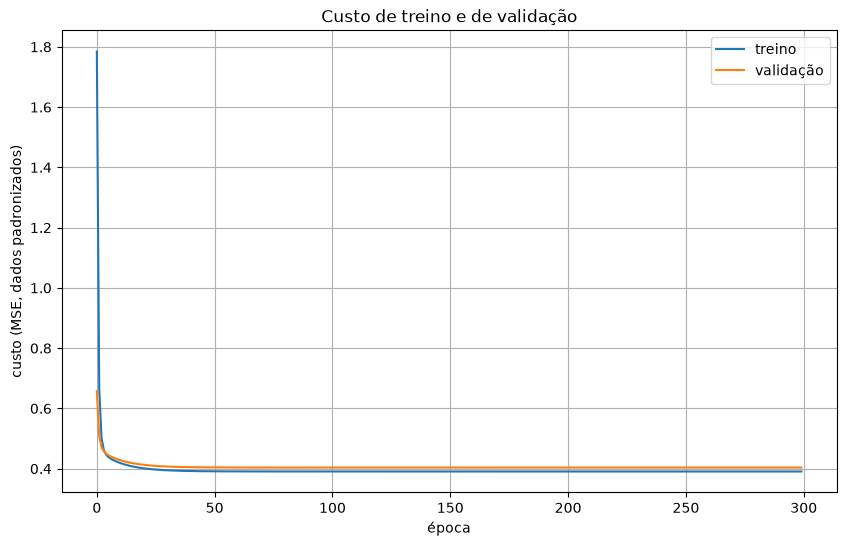

In [11]:
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='treino')
plt.plot(val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

## Avaliação no teste

O conjunto de teste não participou do treino nem foi olhado até agora. Calculamos o RMSE em dólares (desfazendo a padronização da saída) e comparamos com um **baseline** ingênuo: prever sempre o preço médio do treino, para todo mundo.

In [12]:
model.eval()
with torch.no_grad():
    y_pred_test = model(x_test)

y_pred_test_usd = y_scaler.inverse_transform(y_pred_test.numpy())
y_test_usd = y_test.to_numpy().reshape(-1, 1)

rmse_test = np.sqrt(np.mean((y_pred_test_usd - y_test_usd) ** 2))
print(f'RMSE no teste (modelo): US$ {rmse_test:,.0f}')

RMSE no teste (modelo): US$ 72,129


In [13]:
baseline_pred = np.full_like(y_test_usd, y_train.mean())
rmse_baseline = np.sqrt(np.mean((baseline_pred - y_test_usd) ** 2))

print(f'RMSE no teste (baseline = média do treino): US$ {rmse_baseline:,.0f}')
print(f'Redução de erro em relação ao baseline: {100 * (1 - rmse_test / rmse_baseline):.1f}%')

RMSE no teste (baseline = média do treino): US$ 114,992
Redução de erro em relação ao baseline: 37.3%


## Os 8 pesos aprendidos

`model.weight` guarda um peso por variável de entrada. Como cada variável foi padronizada (média 0, desvio padrão 1), o peso mede o efeito de **1 desvio padrão** de variação naquela variável sobre o preço padronizado — por isso os 8 pesos são comparáveis diretamente entre si, em vez de dependerem da unidade original de cada variável (dólares de renda, nº de cômodos, graus de latitude, etc., que não são comparáveis).

In [14]:
weights = model.weight.detach().numpy().flatten()
w_df = pd.DataFrame({'variável': X.columns, 'peso (padronizado)': weights})
w_df = w_df.sort_values('peso (padronizado)', ascending=False).reset_index(drop=True)
w_df

,variável,peso (padronizado)
0,MedInc,0.733706
1,AveBedrms,0.301026
2,HouseAge,0.105508
3,Population,-0.000764
4,AveOccup,-0.036026
5,AveRooms,-0.258822
6,Longitude,-0.750440
7,Latitude,-0.772244


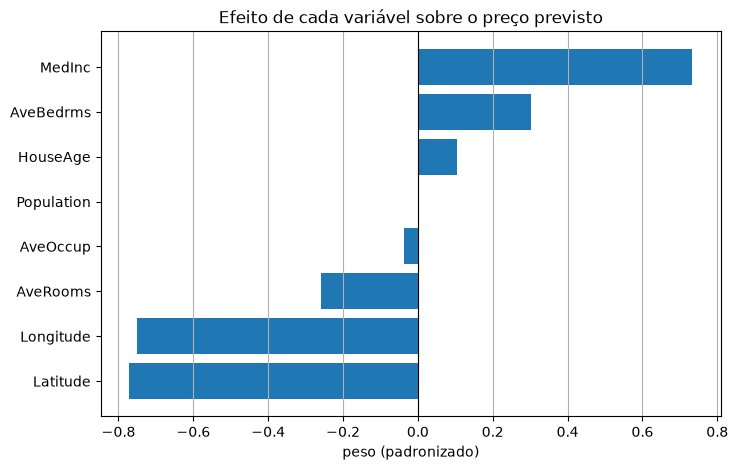

In [15]:
plt.figure(figsize=(8, 5))
plt.barh(w_df['variável'], w_df['peso (padronizado)'])
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('peso (padronizado)')
plt.title('Efeito de cada variável sobre o preço previsto')
plt.gca().invert_yaxis()
plt.grid(True, axis='x')
plt.show()

**Resposta (pesos e padronização):**

Pesos aprendidos (padronizados), do mais positivo ao mais negativo:

| variável | peso | efeito |
|---|---|---|
| `MedInc` | **+0,734** | aumenta mais o preço |
| `AveBedrms` | +0,301 | aumenta o preço |
| `HouseAge` | +0,106 | aumenta pouco o preço |
| `Population` | ≈ 0,00 | quase nenhum efeito |
| `AveOccup` | −0,036 | quase nenhum efeito |
| `AveRooms` | −0,259 | diminui o preço |
| `Longitude` | −0,750 | diminui o preço |
| `Latitude` | **−0,772** | diminui mais o preço |

**O que mais aumenta o preço previsto** é `MedInc` (renda média do quarteirão): 1 desvio-padrão de renda a mais aumenta o preço previsto em 0,73 desvio-padrão — de longe o efeito isolado mais forte, confirmando o que já víamos no gráfico de dispersão. `AveBedrms` também entra com peso positivo considerável.

**O que mais diminui o preço previsto** são `Latitude` e `Longitude`, com os dois maiores pesos em módulo do modelo (ainda maiores que o de `MedInc`). Isso é esperado dado o gráfico de dispersão: preço varia fortemente com a posição geográfica (litoral valorizado, regiões da Baía de SF e de LA), mas de forma **não-linear** (dois polos de preço alto, não uma reta); o modelo linear só consegue aproximar essa geografia por uma única inclinação em cada eixo — daqui os pesos grandes e negativos, capturando a tendência "quanto mais ao norte/mais para dentro do estado, em média mais barato", sem conseguir representar os dois polos separadamente.

`Population` e `AveOccup` praticamente não importam (pesos perto de zero): a população do quarteirão ou o número de moradores por domicílio, isoladamente, quase não ajudam a prever o preço.

Um ponto de atenção: `AveRooms` tem peso **negativo** (-0,26), o que à primeira vista é contraintuitivo (mais cômodos deveria, em geral, significar imóvel maior e mais caro). Isso é um sintoma de **colinearidade** entre `AveRooms` e `AveBedrms` (ambas medem "tamanho do domicílio em cômodos"): quando duas variáveis de entrada são parecidas, a regressão linear pode distribuir o efeito combinado delas de forma pouco intuitiva entre as duas, inclusive com sinais opostos — por isso o sinal de uma variável isolada nem sempre tem uma leitura causal direta quando há entradas correlacionadas.

**Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas:** sem padronização, cada peso $w_i$ seria "preço previsto por 1 unidade da variável $i$ em sua escala original" — e essas escalas são completamente diferentes (`Population` varia em milhares, `Latitude`/`Longitude` em dezenas de graus, `AveBedrms` em unidades). Um peso pequeno para `Population` não significaria necessariamente "pouco importante": poderia ser só porque 1 habitante a mais é uma mudança desprezível, enquanto 1 grau de latitude é uma mudança geográfica enorme. Depois da padronização, "1 unidade" de qualquer variável passa a significar a mesma coisa — 1 desvio-padrão daquela variável nos dados de treino — e aí, sim, o tamanho do peso reflete o efeito relativo de cada variável sobre o preço, de forma comparável entre todas as 8.

## Conclusão

O modelo chega a um RMSE de teste de **US\$ 72.129**, contra **US\$ 114.992** do baseline que sempre prevê o preço médio do treino — uma redução de **37,3%** no erro. Isso mostra que a regressão linear aprende algo real sobre os dados (sobretudo o efeito forte de `MedInc` e o padrão geográfico de `Latitude`/`Longitude`), mas o erro típico ainda corresponde a cerca de **35% do preço médio** (~US\$ 207 mil) — bem mais alto, proporcionalmente, do que o erro de ~8% obtido no 2.6 para salários.

**O modelo é bom o suficiente?** Para uma primeira abordagem, não: um erro médio de ~US\$ 72 mil num preço médio de ~US\$ 207 mil é grande demais para decisões práticas (por exemplo, avaliar um imóvel individual). O motivo principal é estrutural, não de treinamento: como visto na análise dos pesos e nos gráficos de dispersão, o preço depende de forma **não-linear** de variáveis importantes como a localização geográfica (dois polos de preço alto, em vez de uma tendência contínua com `Latitude`/`Longitude`), e há **colinearidade** entre variáveis como `AveRooms` e `AveBedrms`, que uma reta não consegue desembaraçar. As curvas de treino e validação ficam praticamente coladas e estabilizam rápido (poucas dezenas de épocas), o que indica que o modelo **não está mal treinado nem overfitando** — ele simplesmente não tem expressividade suficiente para o problema (é um caso de *underfitting* estrutural, viés alto).

**O que eu tentaria para melhorar:**
- Features não-lineares: por exemplo combinar `Latitude`/`Longitude` (ou usar a distância até a costa/até SF e LA) em vez de usá-las isoladas e lineares, ou incluir termos polinomiais/interações.
- Tratar a colinearidade entre `AveRooms` e `AveBedrms` (por exemplo, usar a proporção `AveBedrms / AveRooms` em vez das duas variáveis brutas).
- Remover ou tratar outliers extremos (por exemplo, `AveRooms` chega a ~142 e `AveOccup` a ~1.243 em alguns quarteirões, bem fora do padrão da maioria dos dados).
- Ir além de um modelo linear: uma rede com uma ou duas camadas escondidas (não-linear) deveria capturar melhor o efeito geográfico e as interações entre variáveis, ainda usando o mesmo pipeline de treino/validação/teste.